# Question 4 — Optical Flow ("Optical-flow dance video")
**Computer Vision Lab · Assignment 4**

**Input.** `video/input_taichi_selfie.mp4` – a tai-chi arm-movement clip (three people standing side by side, static camera, 478×850 px, 30 fps, **20 s = 600 frames**, with audio). *The assignment suggests 1–2 min; the clip I was given is 20 s – the pipeline is length-independent.*

**What is produced**
1. **SIFT features** in every frame, tracked into the next frame; the *moving* features are drawn as colour-coded motion vectors.
2. **Dense colour-coded optical flow** (DIS algorithm) for every frame pair.
3. **`video/flow_dance_on_black.mp4`** – the flow (dense colour field + SIFT motion vectors + short motion trails) drawn on a **black background**, with the original audio. Also `video/flow_vs_original_side_by_side.mp4` for comparison.
4. **`Q4_algorithm_description.txt`** – a text file describing the algorithm and every parameter (required by the assignment).

**Colour code (Middlebury-style):** *hue* = direction of motion (red → right, yellow/green → down, cyan → left, blue/purple → up), *brightness* = speed (px / frame). The colour wheel below is also printed in the bottom-left corner of the output video.

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd, subprocess, time, os
from pathlib import Path

np.random.seed(0)
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
Path("video").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
SRC = "video/input_taichi_selfie.mp4"
cap = cv2.VideoCapture(SRC)
N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
FPS = cap.get(cv2.CAP_PROP_FPS)
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()
print(f"{N} frames, {FPS:.1f} fps, {W}x{H}, duration {N/FPS:.1f} s")


600 frames, 30.0 fps, 478x850, duration 20.0 s


## 1. Algorithm
For every consecutive frame pair (t, t+1):
1. **Dense flow – DIS** (Dense Inverse Search, Kroeger et al. 2016, `cv2.DISOpticalFlow`, preset *medium*): patch-based inverse Lucas-Kanade search on an image pyramid, followed by densification and variational refinement. It handles the fast arm swings well and runs in real-time. The flow `(u, v)` of every pixel is converted to polar form: angle → hue, magnitude → value (brightness) with a fixed normalisation (`|flow| = 6 px/frame` → full brightness) so the colours are comparable across frames.
2. **SIFT features** are detected in frame t (`cv2.SIFT_create`, contrast threshold 0.02, ≤ 1500 keypoints, restricted to the picture area – the black letterbox bars are excluded).
3. **Sparse flow of the SIFT features** – pyramidal **Lucas–Kanade** (`cv2.calcOpticalFlowPyrLK`, 21×21 window, 3 pyramid levels) from t → t+1, then **forward–backward verification** (track back to frame t, keep features whose round-trip error is < 0.5 px). The result is a set of reliable feature motion vectors.
4. **Moving features** = verified features whose displacement is ≥ 0.8 px/frame *after subtracting the background motion* (median flow of all verified features – ≈ 0 here because the camera is static, but it makes the method robust to hand-shake).
5. **Rendering on black:** dense colour flow (pixels slower than 0.5 px/frame set to black) + each moving SIFT feature drawn as a coloured dot with an arrow (length ×3) + a fading 8-frame trail of its motion; frame counter and colour wheel in the margin.

picture area: rows 84 to 766  (letterbox bars excluded from feature detection)


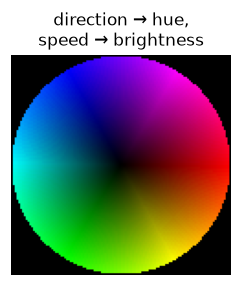

In [2]:
P = dict(
    dis_preset=cv2.DISOPTICAL_FLOW_PRESET_MEDIUM,
    mag_full=6.0,
    mag_dense_min=0.5,
    sift_contrast=0.02,
    sift_max=1500,
    lk_win=(21, 21),
    lk_levels=3,
    fb_thresh=0.5,
    move_thresh=0.8,
    arrow_gain=3.0,
    trail=8,
)


def flow_to_color(flow, mag_full=P["mag_full"], mag_min=0.0):
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1], angleInDegrees=True)
    hsv = np.zeros(flow.shape[:2] + (3,), np.uint8)
    hsv[..., 0] = (ang / 2).astype(np.uint8)
    hsv[..., 1] = 255
    hsv[..., 2] = np.clip(255 * mag / mag_full, 0, 255).astype(np.uint8)
    hsv[mag < mag_min] = 0
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR), mag, ang


def color_of(vx, vy, mag_full=P["mag_full"], floor=170):
    """BGR colour of a single motion vector (same code as the dense flow, but brightness has a floor so that dots are always visible)"""
    ang = (np.degrees(np.arctan2(vy, vx)) % 360) / 2
    c = cv2.cvtColor(
        np.uint8(
            [[[ang, 255, floor + (255 - floor) * min(1, np.hypot(vx, vy) / mag_full)]]]
        ),
        cv2.COLOR_HSV2BGR,
    )[0, 0]
    return tuple(int(v) for v in c)


# picture area (the clip has black letterbox bars above and below)
cap = cv2.VideoCapture(SRC)
ok, f0 = cap.read()
cap.release()
rows = np.where(cv2.cvtColor(f0, cv2.COLOR_BGR2GRAY).mean(1) > 12)[0]
Y0, Y1 = rows.min(), rows.max() + 1
print(
    "picture area: rows",
    Y0,
    "to",
    Y1,
    " (letterbox bars excluded from feature detection)",
)


# colour wheel (legend)
def colour_wheel(size=120):
    yy, xx = np.mgrid[-1 : 1 : size * 1j, -1 : 1 : size * 1j]
    r = np.hypot(xx, yy)
    fl = np.dstack([xx, yy]) * P["mag_full"]
    img, _, _ = flow_to_color(fl.astype(np.float32))
    img[r > 1] = 0
    return img


wheel = colour_wheel()
cv2.imwrite(str(OUT / "q4_colour_wheel.png"), wheel)
plt.figure(figsize=(2.6, 2.6))
plt.imshow(cv2.cvtColor(wheel, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("direction → hue,\nspeed → brightness")
plt.show()


## 2. Run the pipeline over all frames (writes the flow-dance video)

In [3]:
sift = cv2.SIFT_create(nfeatures=P["sift_max"], contrastThreshold=P["sift_contrast"])
dis = cv2.DISOpticalFlow.create(P["dis_preset"])
cap = cv2.VideoCapture(SRC)
ok, prev = cap.read()
prev_g = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY)
tmp_black, tmp_sbs = "video/_tmp_black.mp4", "video/_tmp_sbs.mp4"
vw_b = cv2.VideoWriter(tmp_black, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
vw_s = cv2.VideoWriter(tmp_sbs, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (2 * W, H))
mask_pic = np.zeros((H, W), np.uint8)
mask_pic[Y0:Y1] = 255
stats = []
trails = []
keep_frames = {}
t0 = time.time()
idx = 0
SAMPLE = set(np.linspace(20, N - 2, 8).astype(int))
while True:
    ok, cur = cap.read()
    if not ok:
        break
    cur_g = cv2.cvtColor(cur, cv2.COLOR_BGR2GRAY)
    # --- dense flow (DIS) ---
    flow = dis.calc(prev_g, cur_g, None)
    dense, mag, ang = flow_to_color(flow, mag_min=P["mag_dense_min"])
    # --- SIFT + LK with forward-backward check ---
    kp = sift.detect(prev_g, mask_pic)
    pts = np.float32([k.pt for k in kp]).reshape(-1, 1, 2)
    n_sift = len(pts)
    n_ok = n_move = 0
    segs = []
    if n_sift:
        nxt, st, _ = cv2.calcOpticalFlowPyrLK(
            prev_g, cur_g, pts, None, winSize=P["lk_win"], maxLevel=P["lk_levels"]
        )
        back, st2, _ = cv2.calcOpticalFlowPyrLK(
            cur_g, prev_g, nxt, None, winSize=P["lk_win"], maxLevel=P["lk_levels"]
        )
        fb = np.linalg.norm((pts - back).reshape(-1, 2), axis=1)
        good = (st.ravel() == 1) & (st2.ravel() == 1) & (fb < P["fb_thresh"])
        v = (nxt - pts).reshape(-1, 2)[good]
        p0 = pts.reshape(-1, 2)[good]
        n_ok = int(good.sum())
        if n_ok:
            bg = np.median(v, axis=0)
            vr = v - bg  # subtract background (camera) motion
            mv = np.linalg.norm(vr, axis=1) >= P["move_thresh"]
            n_move = int(mv.sum())
            segs = [(p0[i], vr[i]) for i in np.where(mv)[0]]
    trails.append(segs)
    trails = trails[-P["trail"] :]
    # --- render on black ---
    canvas = (dense * 0.85).astype(np.uint8)
    for age, sg in enumerate(trails[:-1]):  # fading trails of older motion vectors
        fade = (age + 1) / len(trails)
        for p, vv in sg:
            cv2.circle(
                canvas,
                (int(p[0]), int(p[1])),
                1,
                tuple(int(c * fade) for c in color_of(*vv)),
                -1,
            )
    for p, vv in segs:
        col = color_of(*vv)
        q = p + P["arrow_gain"] * vv
        cv2.arrowedLine(
            canvas,
            (int(p[0]), int(p[1])),
            (int(q[0]), int(q[1])),
            col,
            1,
            cv2.LINE_AA,
            tipLength=0.35,
        )
        cv2.circle(canvas, (int(p[0]), int(p[1])), 2, (255, 255, 255), -1)
    canvas[H - 130 : H - 10, 10:130] = np.maximum(
        canvas[H - 130 : H - 10, 10:130], wheel
    )
    cv2.putText(
        canvas,
        "dense flow (DIS) + moving SIFT features (LK)",
        (8, 18),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.42,
        (200, 200, 200),
        1,
        cv2.LINE_AA,
    )
    cv2.putText(
        canvas,
        f"frame {idx+1}/{N-1}  t={idx/FPS:4.1f}s",
        (8, H - 138),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.42,
        (200, 200, 200),
        1,
        cv2.LINE_AA,
    )
    vw_b.write(canvas)
    vw_s.write(np.hstack([cur, canvas]))
    if idx in SAMPLE:
        keep_frames[idx] = (cur.copy(), canvas.copy())
    # --- statistics (per frame) ---
    third = np.array_split(np.arange(W), 3)
    sel = mag > P["mag_dense_min"]
    stats.append(
        dict(
            frame=idx + 1,
            t=(idx + 1) / FPS,
            sift=n_sift,
            tracked=n_ok,
            moving=n_move,
            mean_speed_moving=(
                float(np.mean([np.linalg.norm(vv) for _, vv in segs])) if segs else 0.0
            ),
            moving_pixels_pct=100 * sel[Y0:Y1].mean(),
            mean_mag=float(mag[Y0:Y1].mean()),
            p95_mag=float(np.percentile(mag[Y0:Y1], 95)),
            left=float(mag[Y0:Y1][:, third[0]].mean()),
            centre=float(mag[Y0:Y1][:, third[1]].mean()),
            right=float(mag[Y0:Y1][:, third[2]].mean()),
            bg_dx=float(bg[0]) if n_ok else 0,
            bg_dy=float(bg[1]) if n_ok else 0,
        )
    )
    prev_g = cur_g
    idx += 1
cap.release()
vw_b.release()
vw_s.release()
print(f"processed {idx} frame pairs in {time.time()-t0:.0f} s")

# re-encode to H.264 and attach the original audio track
for tmp, outp in [
    (tmp_black, "video/flow_dance_on_black.mp4"),
    (tmp_sbs, "video/flow_vs_original_side_by_side.mp4"),
]:
    cmd = [
        "ffmpeg",
        "-y",
        "-loglevel",
        "error",
        "-i",
        tmp,
        "-i",
        SRC,
        "-map",
        "0:v",
        "-map",
        "1:a?",
        "-c:v",
        "libx264",
        "-crf",
        "20",
        "-preset",
        "veryfast",
        "-pix_fmt",
        "yuv420p",
        "-c:a",
        "aac",
        "-shortest",
        outp,
    ]
    subprocess.run(cmd, check=True)
    os.remove(tmp)
print(
    {
        p: round(os.path.getsize(p) / 1e6, 2)
        for p in [
            "video/flow_dance_on_black.mp4",
            "video/flow_vs_original_side_by_side.mp4",
        ]
    },
    "MB",
)
df = pd.DataFrame(stats)
df.round(3).to_csv(OUT / "q4_per_frame_statistics.csv", index=False)


processed 599 frame pairs in 64 s
{'video/flow_dance_on_black.mp4': 8.81, 'video/flow_vs_original_side_by_side.mp4': 10.77} MB


## 3. Result: original frames vs. colour-coded optical flow on black
Eight frames sampled evenly through the clip (top = original, bottom = flow-dance frame).

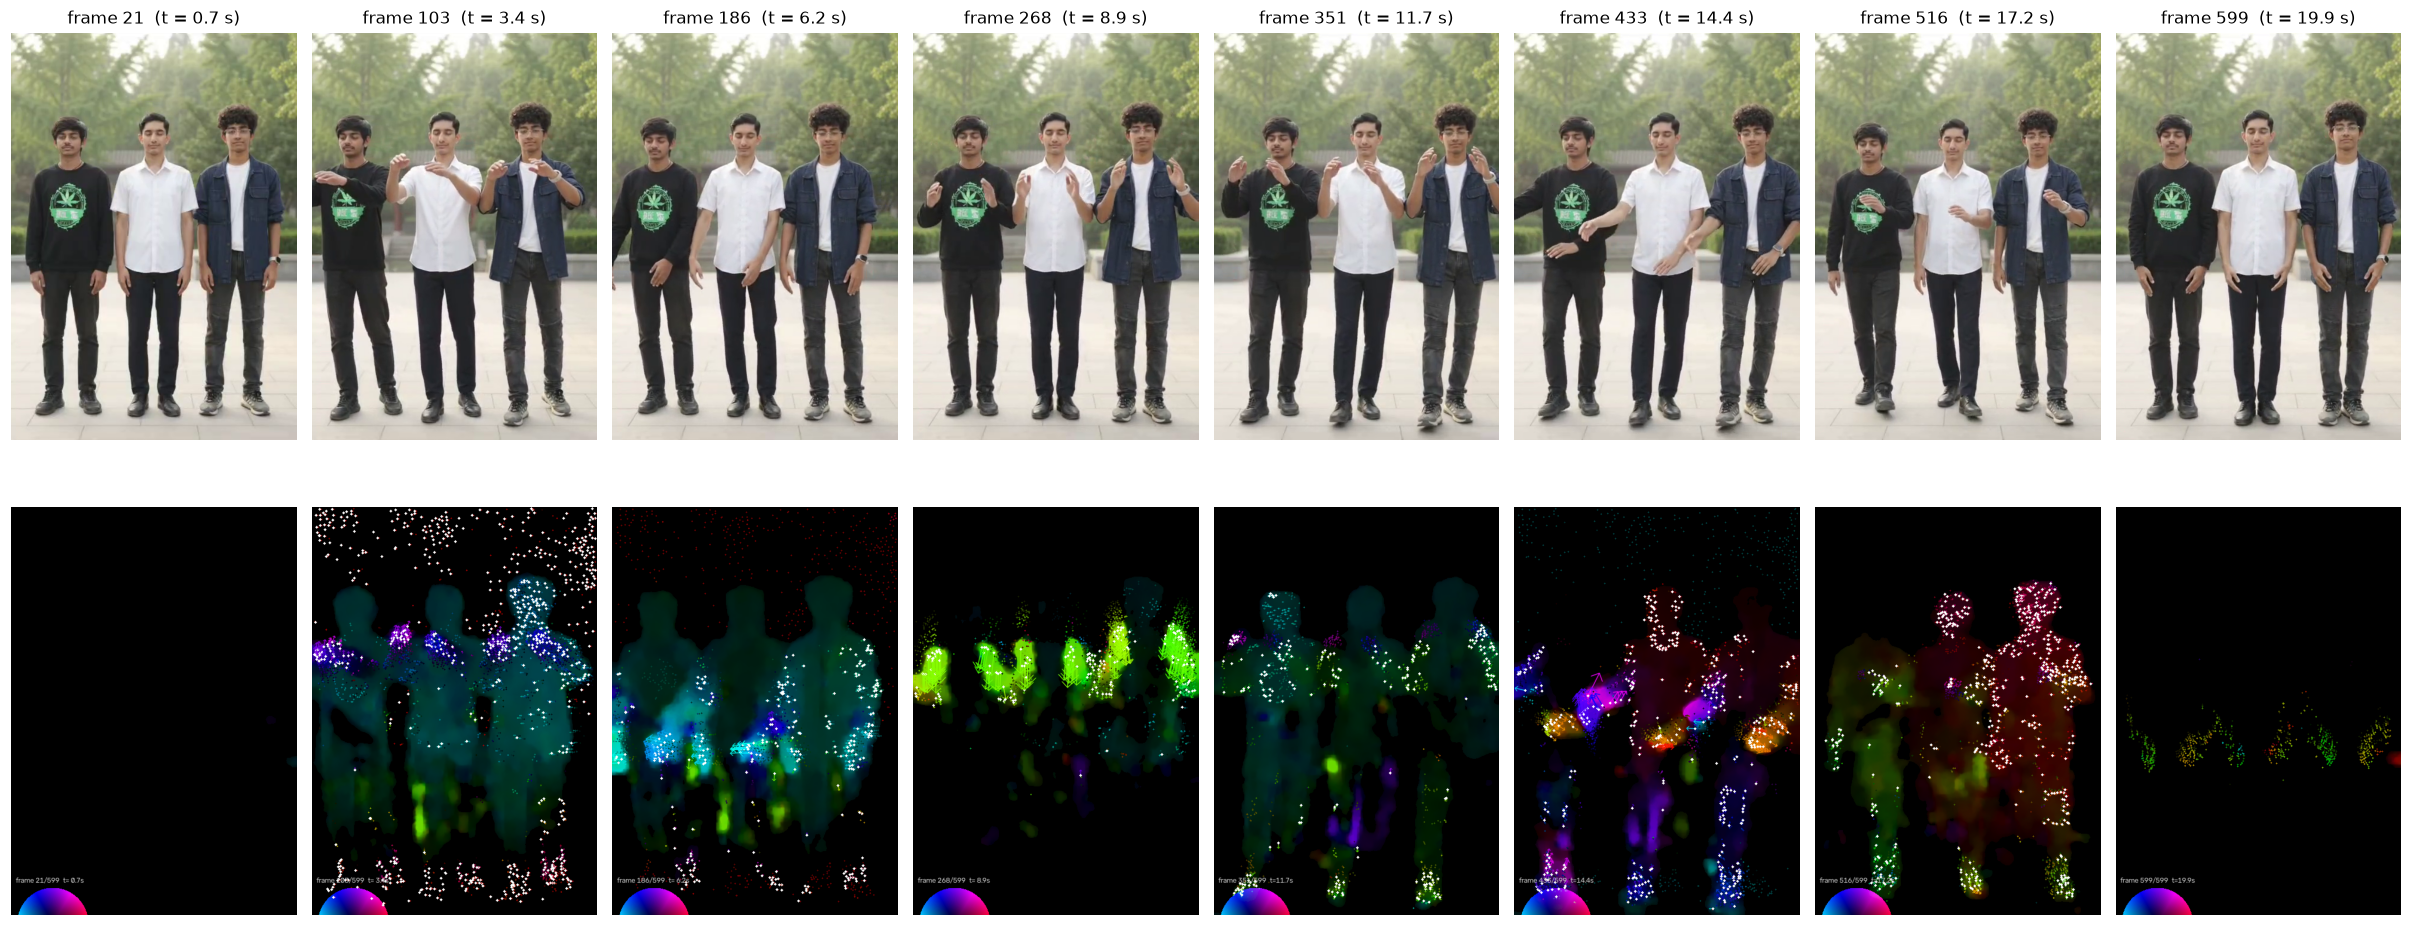

In [4]:
ks = sorted(keep_frames)
fig, axs = plt.subplots(2, 8, figsize=(22, 9.5))
for j, k in enumerate(ks):
    a, b = keep_frames[k]
    axs[0, j].imshow(cv2.cvtColor(a[Y0:Y1], cv2.COLOR_BGR2RGB))
    axs[1, j].imshow(cv2.cvtColor(b[Y0:Y1], cv2.COLOR_BGR2RGB))
    axs[0, j].set_title(f"frame {k+1}  (t = {k/FPS:.1f} s)")
    axs[0, j].axis("off")
    axs[1, j].axis("off")
plt.tight_layout()
plt.savefig(OUT / "q4_frame_montage.png", dpi=110)
plt.show()


### Close-up of a single frame (SIFT keypoints, tracked feature vectors, dense flow)

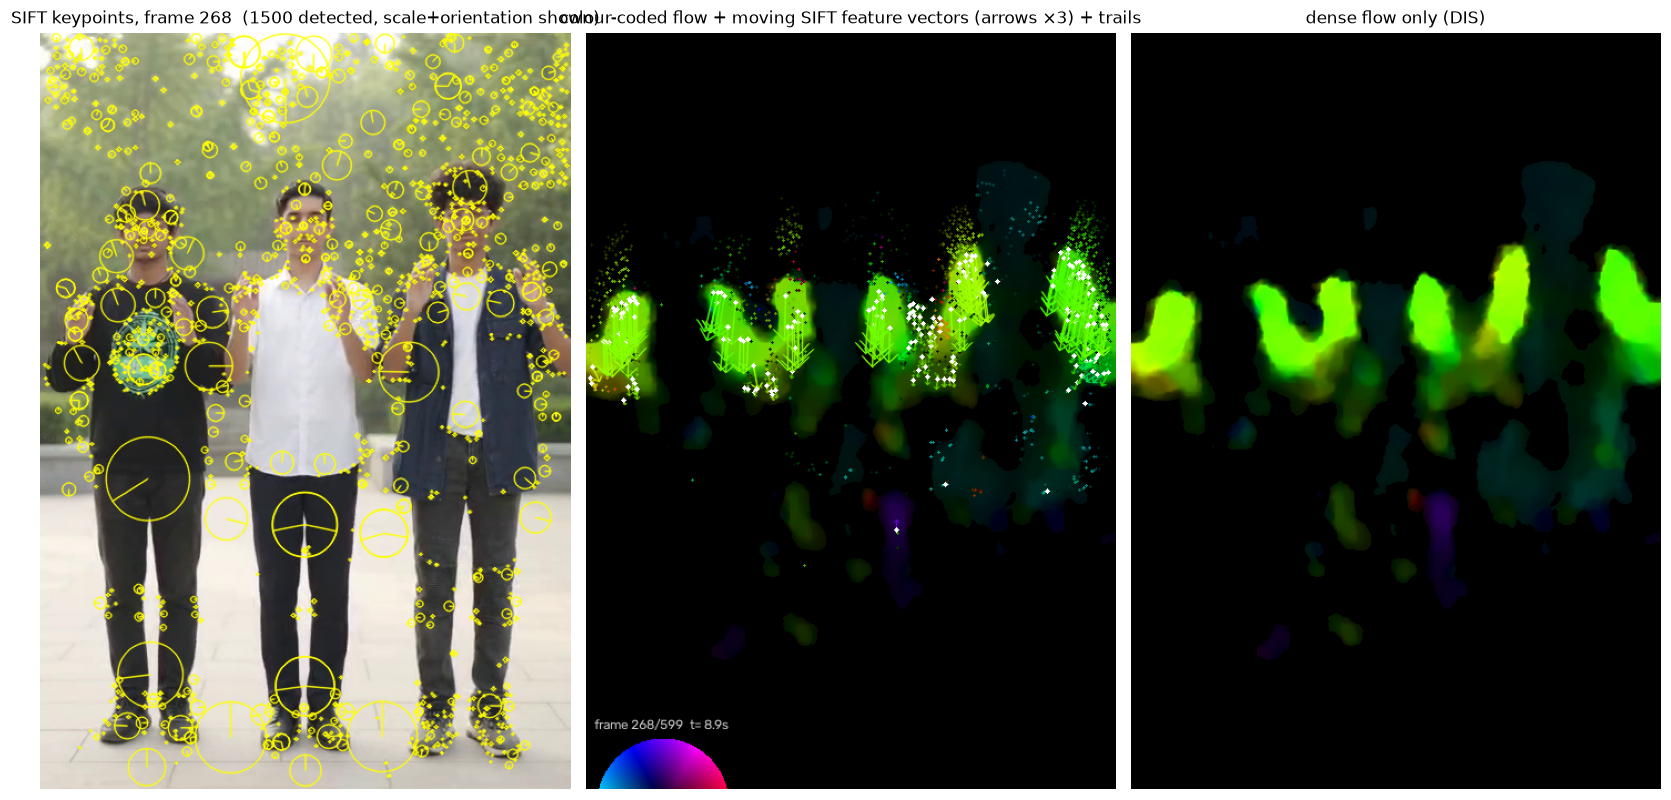

In [5]:
k = ks[3]
a, b = keep_frames[k]
cap = cv2.VideoCapture(SRC)
cap.set(cv2.CAP_PROP_POS_FRAMES, k)
_, f_prev = cap.read()
_, f_cur = cap.read()
cap.release()
gp = cv2.cvtColor(f_prev, cv2.COLOR_BGR2GRAY)
kp_ = sift.detect(gp, mask_pic)
vis_kp = cv2.drawKeypoints(
    f_prev,
    kp_,
    None,
    color=(0, 255, 255),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
)
fig, axs = plt.subplots(1, 3, figsize=(15, 8))
axs[0].imshow(cv2.cvtColor(vis_kp[Y0:Y1], cv2.COLOR_BGR2RGB))
axs[0].set_title(
    f"SIFT keypoints, frame {k+1}  ({len(kp_)} detected, scale+orientation shown)"
)
axs[1].imshow(cv2.cvtColor(b[Y0:Y1], cv2.COLOR_BGR2RGB))
axs[1].set_title("colour-coded flow + moving SIFT feature vectors (arrows ×3) + trails")
dense_only, _, _ = flow_to_color(
    dis.calc(gp, cv2.cvtColor(f_cur, cv2.COLOR_BGR2GRAY), None),
    mag_min=P["mag_dense_min"],
)
axs[2].imshow(cv2.cvtColor(dense_only[Y0:Y1], cv2.COLOR_BGR2RGB))
axs[2].set_title("dense flow only (DIS)")
for a_ in axs:
    a_.axis("off")
plt.tight_layout()
plt.savefig(OUT / "q4_closeup.png", dpi=120)
plt.show()


## 4. Quantitative analysis of the motion
Mean flow magnitude (px/frame) over time, in total and for the three people (left / centre / right third of the picture); number of SIFT features detected, tracked and found moving.

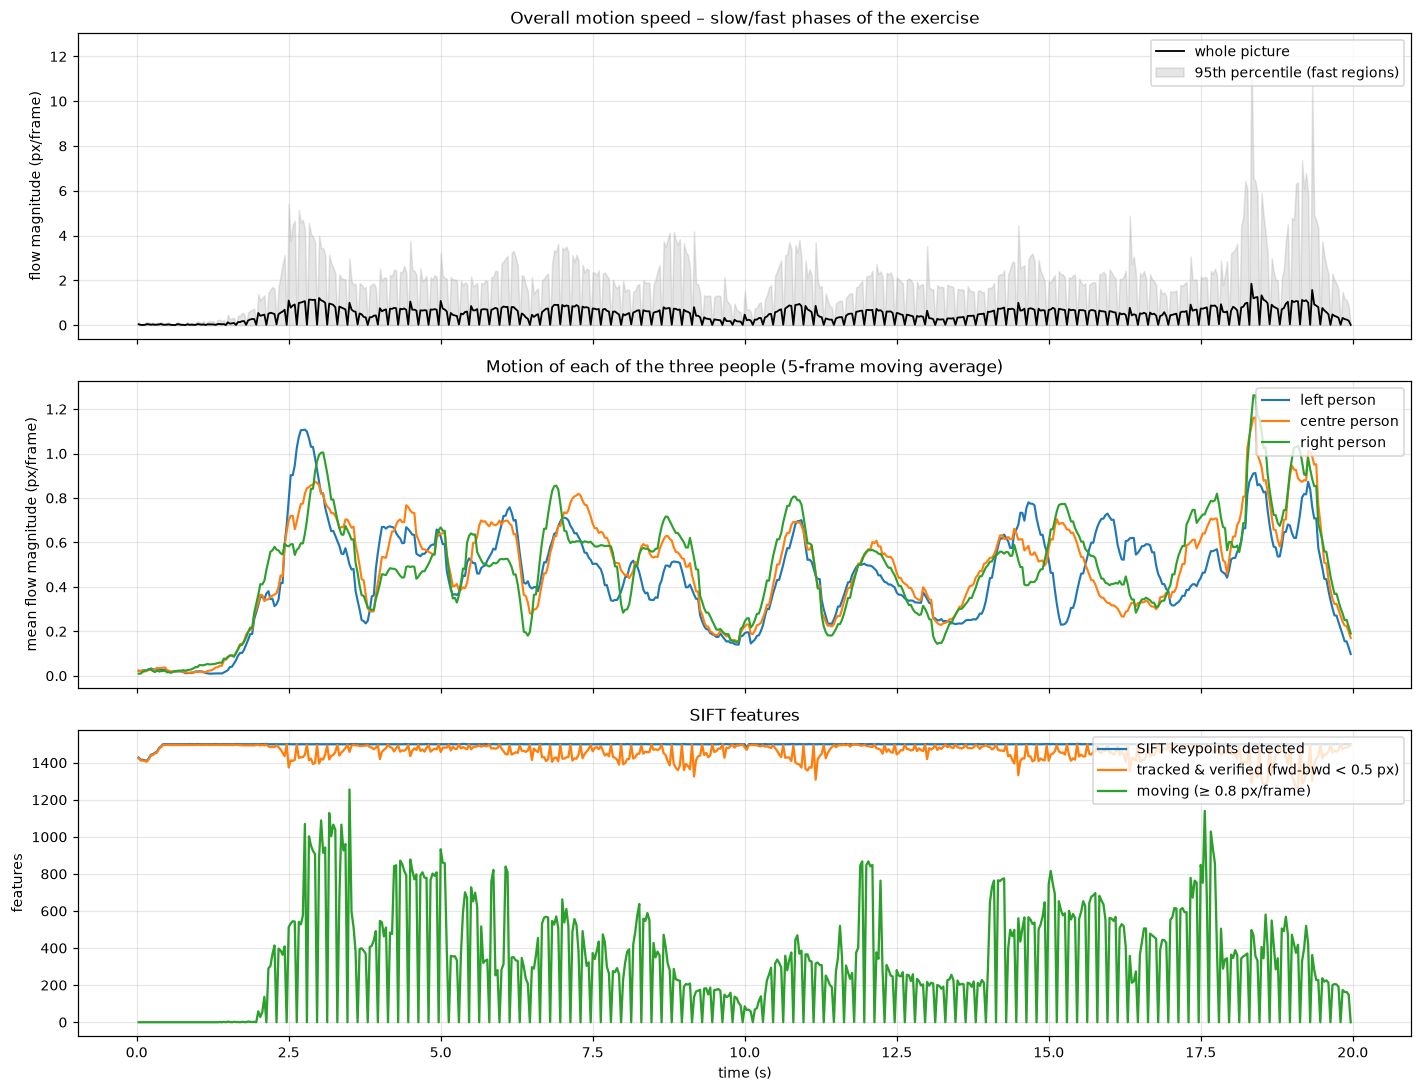

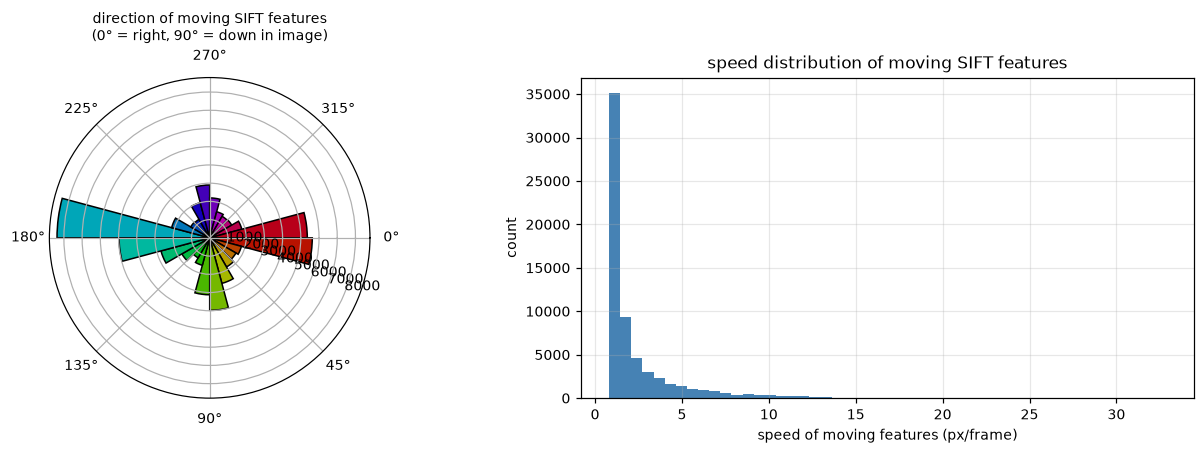

moving SIFT vectors analysed: 64366; median speed 1.34 px/frame, 95th percentile 7.88 px/frame, max 32.8
direction share: right (-45..45°) 27 %, down (45..135°) 22 %, left (|angle|>135°) 33 %, up (-135..-45°) 17 %
background (camera) motion estimate: median |dx|, |dy| = 0.081, 0.000 px/frame
fastest moment: t = 18.33 s (mean flow 1.85 px/frame, 95th pct 12.4); slowest 1-s window starts at t = -0.0 s
         sift  tracked   moving  mean_speed_moving  moving_pixels_pct  mean_mag
mean  1498.92  1459.43   326.38               1.99              26.44      0.47
min   1410.00  1261.00     0.00               0.00               0.00      0.00
max   1502.00  1501.00  1256.00               9.43              52.97      1.85


In [6]:
fig, axs = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
axs[0].plot(df.t, df.mean_mag, "k", lw=1.2, label="whole picture")
axs[0].fill_between(
    df.t, 0, df.p95_mag, color="gray", alpha=0.2, label="95th percentile (fast regions)"
)
axs[0].set_ylabel("flow magnitude (px/frame)")
axs[0].legend(loc="upper right")
axs[0].set_title("Overall motion speed – slow/fast phases of the exercise")
axs[0].grid(alpha=0.3)
for c, col in [("left", "tab:blue"), ("centre", "tab:orange"), ("right", "tab:green")]:
    axs[1].plot(
        df.t,
        df[c].rolling(5, center=True, min_periods=1).mean(),
        color=col,
        label=f"{c} person",
        lw=1.4,
    )
axs[1].set_ylabel("mean flow magnitude (px/frame)")
axs[1].legend(loc="upper right")
axs[1].set_title("Motion of each of the three people (5-frame moving average)")
axs[1].grid(alpha=0.3)
axs[2].plot(df.t, df.sift, label="SIFT keypoints detected")
axs[2].plot(df.t, df.tracked, label="tracked & verified (fwd-bwd < 0.5 px)")
axs[2].plot(df.t, df.moving, label="moving (≥ 0.8 px/frame)")
axs[2].set_xlabel("time (s)")
axs[2].set_ylabel("features")
axs[2].legend(loc="upper right")
axs[2].set_title("SIFT features")
axs[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "q4_motion_statistics.png", dpi=120)
plt.show()

# direction statistics of moving SIFT vectors across the whole video
cap = cv2.VideoCapture(SRC)
ok, pg = cap.read()
pg = cv2.cvtColor(pg, cv2.COLOR_BGR2GRAY)
dirs = []
spds = []
for i in range(0, N - 1, 3):
    cap.set(cv2.CAP_PROP_POS_FRAMES, i)
    _, a1 = cap.read()
    _, a2 = cap.read()
    g1, g2 = cv2.cvtColor(a1, cv2.COLOR_BGR2GRAY), cv2.cvtColor(a2, cv2.COLOR_BGR2GRAY)
    p_ = np.float32([k.pt for k in sift.detect(g1, mask_pic)]).reshape(-1, 1, 2)
    if len(p_) == 0:
        continue
    n_, s1, _ = cv2.calcOpticalFlowPyrLK(
        g1, g2, p_, None, winSize=P["lk_win"], maxLevel=P["lk_levels"]
    )
    b_, s2, _ = cv2.calcOpticalFlowPyrLK(
        g2, g1, n_, None, winSize=P["lk_win"], maxLevel=P["lk_levels"]
    )
    g_ = (
        (s1.ravel() == 1)
        & (s2.ravel() == 1)
        & (np.linalg.norm((p_ - b_).reshape(-1, 2), axis=1) < P["fb_thresh"])
    )
    v_ = (n_ - p_).reshape(-1, 2)[g_]
    v_ = v_ - np.median(v_, axis=0)
    m_ = np.linalg.norm(v_, axis=1) >= P["move_thresh"]
    dirs += list(np.degrees(np.arctan2(v_[m_, 1], v_[m_, 0])))
    spds += list(np.linalg.norm(v_[m_], axis=1))
cap.release()
dirs, spds = np.array(dirs), np.array(spds)
fig = plt.figure(figsize=(12, 4.2))
ax = fig.add_subplot(121, projection="polar")
hh, edges = np.histogram(np.deg2rad(dirs), bins=24, range=(-np.pi, np.pi))
ax.bar(
    edges[:-1],
    hh,
    width=2 * np.pi / 24,
    align="edge",
    color=[
        np.array(color_of(np.cos(e + 0.13), np.sin(e + 0.13))[::-1]) / 255
        for e in edges[:-1]
    ],
    edgecolor="k",
)
ax.set_theta_direction(-1)
ax.set_title(
    "direction of moving SIFT features\n(0° = right, 90° = down in image)", fontsize=9
)
ax2 = fig.add_subplot(122)
ax2.hist(spds, bins=50, color="steelblue")
ax2.set_xlabel("speed of moving features (px/frame)")
ax2.set_ylabel("count")
ax2.set_title("speed distribution of moving SIFT features")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "q4_direction_speed.png", dpi=120)
plt.show()
frac = lambda lo, hi: 100 * np.mean((dirs >= lo) & (dirs < hi))
print(
    f"moving SIFT vectors analysed: {len(dirs)}; median speed {np.median(spds):.2f} px/frame, 95th percentile {np.percentile(spds, 95):.2f} px/frame, max {spds.max():.1f}"
)
print(
    f"direction share: right (-45..45°) {frac(-45, 45):.0f} %, down (45..135°) {frac(45, 135):.0f} %, left (|angle|>135°) {100*np.mean(np.abs(dirs) >= 135):.0f} %, up (-135..-45°) {frac(-135, -45):.0f} %"
)
print(
    f"background (camera) motion estimate: median |dx|, |dy| = {df.bg_dx.abs().median():.3f}, {df.bg_dy.abs().median():.3f} px/frame"
)
top = df.nlargest(1, "mean_mag").iloc[0]
print(
    f"fastest moment: t = {top.t:.2f} s (mean flow {top.mean_mag:.2f} px/frame, 95th pct {top.p95_mag:.1f}); slowest 1-s window starts at t = {df.mean_mag.rolling(30).mean().idxmin()/FPS - 1:.1f} s"
)
print(
    df[
        [
            "sift",
            "tracked",
            "moving",
            "mean_speed_moving",
            "moving_pixels_pct",
            "mean_mag",
        ]
    ]
    .describe()
    .loc[["mean", "min", "max"]]
    .round(2)
    .to_string()
)


## 6. Observations and limitations
* **What the flow shows.** The arm-raise phases appear as bright purple/blue (upward) patches around the shoulders, the sweeps outwards as green/cyan (down/left) and orange/red (right) blobs at the hands; the three people move almost in unison but with visible phase offsets in the per-person curves. The first and last ~1 s are static (black frames), as expected.
* **Speeds.** Moving SIFT features have a median speed of 1.33 px/frame, a 95th percentile of 7.9 px/frame and a maximum of 33 px/frame (fast hand swings); the whole-picture mean flow peaks at 1.85 px/frame at t ≈ 18.3 s. Directions are spread fairly evenly (right 28 %, down 22 %, left 32 %, up 17 %) – the exercise swings the arms in all directions.
* **Camera.** The median background motion is ≈ 0.08 px/frame horizontally and 0 vertically, i.e. the camera is effectively static; background subtraction is therefore almost a no-op here.
* **Limitations.** In a few frames (e.g. frame 103) scattered dots appear in the foliage / ground: the trees shimmer slightly and the video has compression noise, so a few background features exceed the 0.8 px threshold. Whole-body sway is also coded (dull teal/red body silhouettes) because the body moves slightly, not only the hands. Flow inside the plain black/white clothing is smoothed by the variational step (aperture problem) rather than measured. The clip is 20 s instead of 1–2 min and shows three people rather than a single selfie; all thresholds were set by eye.